# 04 — Apprentissage : One-Class SVM et Isolation Forest (données saines uniquement)
Modules `src/models.py`, `src/training.py`, `src/synthetic.py`, script `train.py` (`python train.py --all`).

**Chaîne de chaque modèle :** `VarianceThreshold` → `StandardScaler` → `ACP (95 % de variance)` → `OneClassSVM (RBF)` ou `IsolationForest`

**Deux niveaux :**
- **zones** (225 par image) : un modèle **par position** ou un modèle **partagé** ; score d'image = **max** ou **moyenne des 3 zones** les plus anormales ;
- **global** (sac de mots ORB/SIFT) : ajouté seulement s'il améliore le critère de sélection.

### Protocole (version 2, après correction de deux problèmes de la version 1)
1. **Toutes les images saines** (train + val, par exemple 209 bouteilles) sont découpées en **5 plis**. Chaque image saine est notée par un modèle entraîné sur les 4 autres plis : c'est un score **hors-pli**, donc non biaisé.
2. **Anomalies synthétiques réalistes** (tache, rayure, fissure, copier-coller, de **1 à 5 %** de l'image) créées sur chaque image saine. Le critère de sélection est l'AUROC hors-pli des images saines contre les images dégradées. **Aucun vrai défaut n'est utilisé.**
3. Détecteur final = **moyenne des 5 modèles**. Calibration et **seuil = 95e centile** des scores hors-pli des images saines, ce qui vise **5 % de fausses alarmes**.
4. Le **test** (vrais défauts) ne sert qu'au compte rendu.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, confusion_matrix, precision_recall_fscore_support
from src.data_loader import load_config
from src.features import compute_features
from src.models import AnomalyDetector
from src.training import healthy_and_synthetic

cfg = load_config(ROOT / "config.yaml"); CATS = cfg["data"]["categories"]
RES = ROOT / "results" / "04_apprentissage"; RES.mkdir(parents=True, exist_ok=True)
F = {c: compute_features(c, cfg, verbose=False) for c in CATS}
DET = {c: AnomalyDetector.load(ROOT / "models" / f"{c}_detector.joblib") for c in CATS}
Z = {c: pd.read_csv(RES / f"selection_zones_{c}.csv") for c in CATS}
GL = {c: pd.read_csv(RES / f"selection_global_{c}.csv") for c in CATS}
SYN = {c: healthy_and_synthetic(F[c], c, cfg)["S"] for c in CATS}
for c in CATS:
    i = DET[c].info
    print(f"{c:9s} → {i['zone']} | {i['agrégation']} | global : {i['global']} | {i['images saines (calibration)']} images saines, {i['plis']} plis")

C:\Users\Admin\Desktop\S9\Computer vision\projet_computer_vision\Visual Anomaly Detection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


bottle    → sans_histogramme | position | ocsvm(nu=0.05, gamma=0.02) | max | global : None | 209 images saines, 5 plis
hazelnut  → sans_histogramme | position | ocsvm(nu=0.05, gamma=scale) | max | global : None | 391 images saines, 5 plis
carpet    → sans_histogramme | shared | ocsvm(nu=0.05, gamma=0.5) | max | global : None | 280 images saines, 5 plis


## 1. Anomalies synthétiques (1 à 5 % de l'image) utilisées pour la sélection

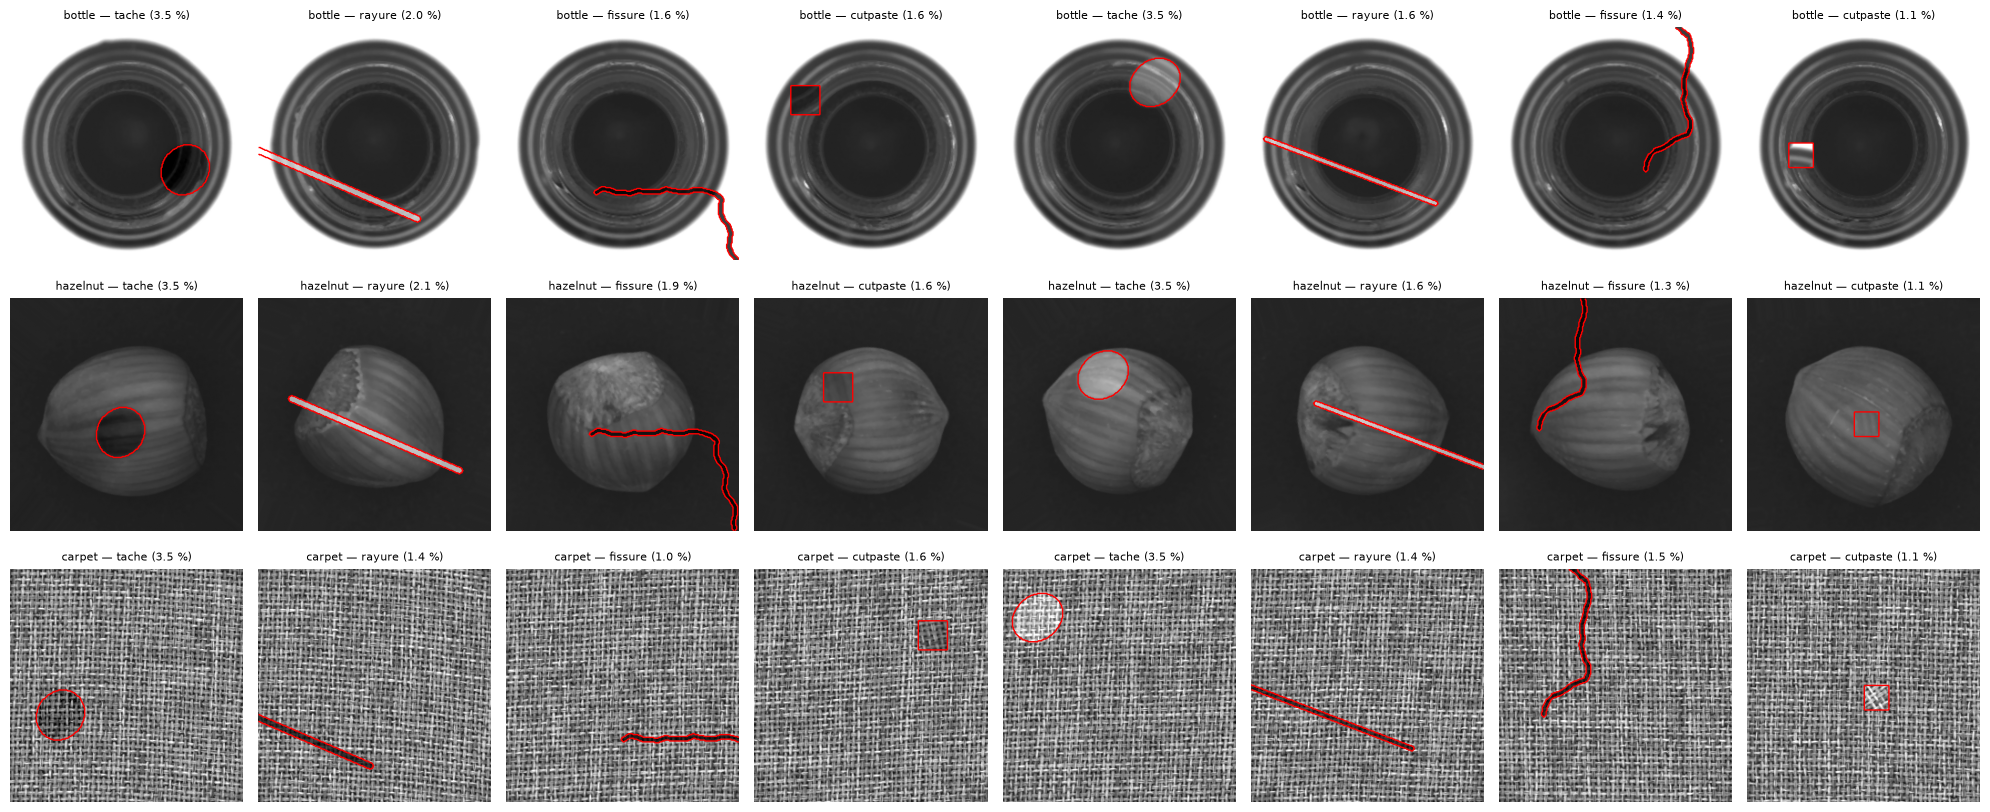

,bottle,hazelnut,carpet
nb défauts,209.00,391.00,280.00
surface min %,0.32,0.31,0.23
surface médiane %,1.61,1.60,1.55
surface max %,4.79,4.96,4.87


In [2]:
fig, axes = plt.subplots(len(CATS), 8, figsize=(20, 2.8 * len(CATS)))
for r, c in enumerate(CATS):
    s = SYN[c]; area = s["masks"].reshape(len(s["masks"]), -1).mean(1) * 100
    for j in range(8):
        ax = axes[r, j]; ax.imshow(s["images"][j], cmap="gray", vmin=0, vmax=255)
        ax.contour(s["masks"][j], levels=[0.5], colors="red", linewidths=1)
        ax.set_title(f"{c} — {s['kinds'][j]} ({area[j]:.1f} %)", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.savefig(RES / "anomalies_synthetiques.png", dpi=110); plt.show()
pd.DataFrame({c: pd.Series(SYN[c]["masks"].reshape(len(SYN[c]["masks"]), -1).mean(1) * 100).describe()[["count", "min", "50%", "max"]]
              for c in CATS}).round(2).rename(index={"count": "nb défauts", "min": "surface min %", "50%": "surface médiane %", "max": "surface max %"})

## 2. Problème 1 résolu ? Le critère de sélection distingue-t-il les configurations ?
Version 1 (défauts de 0,4 %, validation de 42 à 78 images) : sur hazelnut et carpet, **toutes** les configurations obtenaient un critère entre 0,50 et 0,59, et la zone la plus anormale ne tombait sur le défaut synthétique que **20 %** du temps. Le choix se faisait donc au hasard.

Pour être fiable, le critère doit (a) **s'étaler** entre les configurations, (b) **localiser** le défaut synthétique et (c) **classer** les configurations comme le ferait le test. Le point (c) est vérifié a posteriori, pour information.

In [3]:
rows = []
v1 = {"bottle": (0.966, 0.94), "hazelnut": (0.545, 0.20), "carpet": (0.589, 0.21)}   # mesures de la v1 (notebook 04 v1, diagnostic)
for c in CATS:
    d = Z[c]; s = d["AUROC synthétique (sélection)"]
    rows.append({"catégorie": c,
                 "v1 : meilleur critère": v1[c][0], "v1 : zone max sur défaut": f"{v1[c][1]:.0%}",
                 "v2 : critère min-max": f"{s.min():.2f} – {s.max():.2f}",
                 "v2 : zone max sur défaut (config retenue)": f"{d.loc[s.idxmax(), 'zone max sur le défaut synth.']:.0%}",
                 "v2 : corrélation critère / test (Spearman)": round(d[["AUROC synthétique (sélection)", "AUROC test (rapport)"]].corr("spearman").iloc[0, 1], 2)})
crit = pd.DataFrame(rows).set_index("catégorie"); crit.to_csv(RES / "fiabilite_critere.csv"); crit

,v1 : meilleur critère,v1 : zone max sur défaut,v2 : critère min-max,v2 : zone max sur défaut (config retenue),v2 : corrélation critère / test (Spearman)
catégorie,,,,,
bottle,0.966,94%,0.84 – 1.00,99%,0.75
hazelnut,0.545,20%,0.72 – 0.89,85%,0.03
carpet,0.589,21%,0.55 – 0.96,95%,-0.21


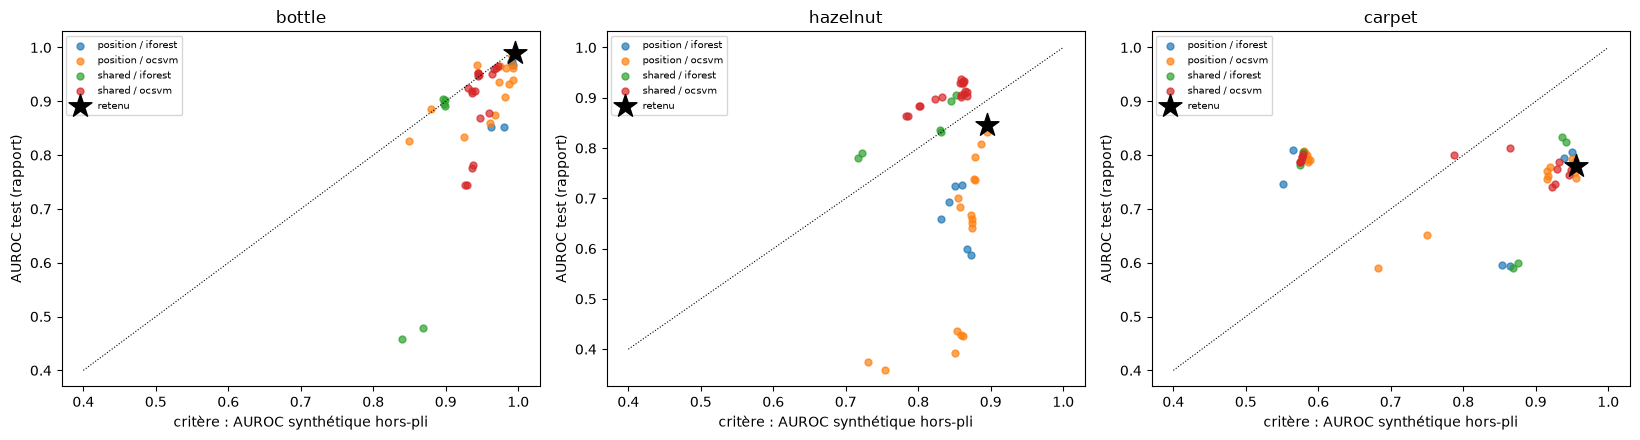

In [4]:
fig, axes = plt.subplots(1, len(CATS), figsize=(5.5 * len(CATS), 4.5))
for ax, c in zip(axes, CATS):
    d = Z[c]
    for (strat, mod), g in d.groupby(["stratégie", "modèle"]):
        ax.scatter(g["AUROC synthétique (sélection)"], g["AUROC test (rapport)"], label=f"{strat} / {mod}", alpha=0.7, s=25)
    b = d.loc[d["AUROC synthétique (sélection)"].idxmax()]
    ax.scatter(b["AUROC synthétique (sélection)"], b["AUROC test (rapport)"], marker="*", s=300, c="k", label="retenu")
    ax.set_title(c); ax.set_xlabel("critère : AUROC synthétique hors-pli"); ax.set_ylabel("AUROC test (rapport)")
    ax.plot([0.4, 1], [0.4, 1], "k:", lw=0.8); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(RES / "synthetique_vs_test.png", dpi=110); plt.show()

In [5]:
for c in CATS:
    t = Z[c].sort_values("AUROC synthétique (sélection)", ascending=False).head(8)
    cols = ["caractéristiques", "stratégie", "modèle", "paramètres", "agrégation", "AUROC synthétique (sélection)",
            "zone max sur le défaut synth.", "AUROC test (rapport)", "temps (s)"]
    print(f"=== {c} : 8 meilleures configurations selon le critère ==="); display(t[cols].round(3).reset_index(drop=True))

=== bottle : 8 meilleures configurations selon le critère ===


,caractéristiques,stratégie,modèle,paramètres,agrégation,AUROC synthétique (sélection),zone max sur le défaut synth.,AUROC test (rapport),temps (s)
0,sans_histogramme,position,ocsvm,"{'nu': 0.05, 'gamma': 0.02}",max,0.996,0.990,0.990,2.076
1,sans_histogramme,position,ocsvm,"{'nu': 0.05, 'gamma': 0.02}",top3,0.996,0.990,0.987,2.076
2,sans_histogramme,position,iforest,{'n_estimators': 100},top3,0.993,0.986,0.967,92.561
3,sans_histogramme,position,ocsvm,"{'nu': 0.05, 'gamma': 'scale'}",top3,0.992,0.947,0.940,2.345
4,toutes,position,ocsvm,"{'nu': 0.05, 'gamma': 0.02}",top3,0.992,0.976,0.962,2.467
5,residu_sobel,position,iforest,{'n_estimators': 100},top3,0.991,0.962,0.975,90.960
6,residu_sobel,position,ocsvm,"{'nu': 0.05, 'gamma': 0.02}",top3,0.991,0.981,0.984,2.097
7,residu_sobel,position,ocsvm,"{'nu': 0.05, 'gamma': 'scale'}",top3,0.991,0.967,0.970,2.494


=== hazelnut : 8 meilleures configurations selon le critère ===


,caractéristiques,stratégie,modèle,paramètres,agrégation,AUROC synthétique (sélection),zone max sur le défaut synth.,AUROC test (rapport),temps (s)
0,sans_histogramme,position,ocsvm,"{'nu': 0.05, 'gamma': 'scale'}",max,0.895,0.847,0.846,14.332
1,sans_histogramme,position,ocsvm,"{'nu': 0.05, 'gamma': 'scale'}",top3,0.894,0.847,0.832,14.337
2,sans_histogramme,position,ocsvm,"{'nu': 0.05, 'gamma': 0.5}",top3,0.887,0.839,0.807,17.319
3,sans_histogramme,position,ocsvm,"{'nu': 0.05, 'gamma': 0.5}",max,0.878,0.839,0.782,17.304
4,sans_histogramme,position,ocsvm,"{'nu': 0.05, 'gamma': 0.02}",top3,0.878,0.808,0.737,12.673
5,sans_histogramme,position,ocsvm,"{'nu': 0.05, 'gamma': 0.02}",max,0.877,0.808,0.738,12.662
6,residu_sobel,position,ocsvm,"{'nu': 0.05, 'gamma': 0.5}",max,0.874,0.790,0.652,14.211
7,residu_sobel,position,ocsvm,"{'nu': 0.05, 'gamma': 'scale'}",max,0.874,0.793,0.642,15.133


=== carpet : 8 meilleures configurations selon le critère ===


,caractéristiques,stratégie,modèle,paramètres,agrégation,AUROC synthétique (sélection),zone max sur le défaut synth.,AUROC test (rapport),temps (s)
0,sans_histogramme,shared,ocsvm,"{'nu': 0.05, 'gamma': 0.5}",max,0.956,0.954,0.779,12.732
1,sans_histogramme,shared,ocsvm,"{'nu': 0.05, 'gamma': 'scale'}",max,0.955,0.954,0.779,12.118
2,sans_histogramme,position,ocsvm,"{'nu': 0.05, 'gamma': 'scale'}",max,0.955,0.954,0.757,2.982
3,sans_histogramme,shared,ocsvm,"{'nu': 0.05, 'gamma': 'scale'}",top3,0.954,0.954,0.776,12.119
4,sans_histogramme,position,ocsvm,"{'nu': 0.05, 'gamma': 0.02}",top3,0.954,0.932,0.789,2.569
5,sans_histogramme,position,ocsvm,"{'nu': 0.05, 'gamma': 'scale'}",top3,0.954,0.954,0.768,2.982
6,sans_histogramme,shared,ocsvm,"{'nu': 0.05, 'gamma': 0.5}",top3,0.954,0.954,0.779,12.732
7,sans_histogramme,position,ocsvm,"{'nu': 0.05, 'gamma': 0.5}",top3,0.952,0.946,0.776,3.396


## 3. Comparaisons demandées par le sujet
Dans chaque groupe, on prend la configuration choisie **par le critère synthétique**, puis on affiche son AUROC de **test**.

In [6]:
def pick(d):
    return d.loc[d["AUROC synthétique (sélection)"].idxmax()]
rows = []
for c in CATS:
    d = Z[c]
    for col in ["modèle", "stratégie", "caractéristiques"]:
        for v, g in d.groupby(col):
            b = pick(g)
            rows.append({"catégorie": c, "comparaison": col, "valeur": v, "AUROC test": b["AUROC test (rapport)"]})
    for v, g in GL[c].groupby("modèle"):
        rows.append({"catégorie": c, "comparaison": "global ORB/SIFT seul", "valeur": v, "AUROC test": pick(g)["AUROC test (rapport)"]})
    for k, v in DET[c].info["combinaisons"].items():
        rows.append({"catégorie": c, "comparaison": "combinaison", "valeur": k, "AUROC test": v["test"]})
cmp_ = pd.DataFrame(rows); cmp_.to_csv(RES / "comparaisons.csv", index=False)
cmp_.pivot_table(index=["comparaison", "valeur"], columns="catégorie", values="AUROC test").round(3)[CATS]

catégorie                              bottle  hazelnut  carpet
comparaison          valeur                                    
caractéristiques     residu_sobel       0.975     0.652   0.791
                     sans_histogramme   0.990     0.846   0.779
                     toutes             0.962     0.425   0.787
combinaison          zones + global     0.979     0.827   0.675
                     zones seules       0.990     0.846   0.779
global ORB/SIFT seul iforest            0.848     0.614   0.447
                     ocsvm              0.910     0.656   0.449
modèle               iforest            0.967     0.588   0.806
                     ocsvm              0.990     0.846   0.779
stratégie            position           0.990     0.846   0.757
                     shared             0.966     0.911   0.779

## 4. Problème 2 résolu ? Le seuil tient-il sur le test ?
Seuil = 95e centile des scores **hors-pli** de toutes les images saines. On vise donc environ **5 %** d'images saines rejetées. Sur le test, le taux observé doit en être proche ; en version 1, il atteignait 15 à 50 %.

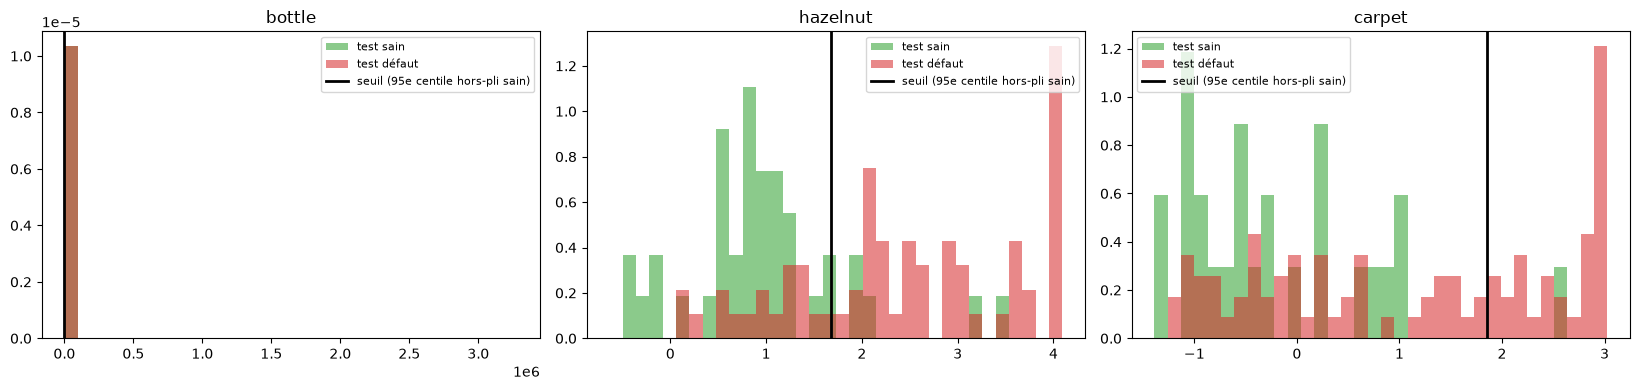

catégorie,bottle,hazelnut,carpet
v1 : AUROC,0.959,0.684,0.699
v1 : sains rejetés,4/20,6/40,14/28
v1 : défauts détectés,61/63,32/70,67/89
v2 : AUROC,0.99,0.846,0.779
v2 : sains rejetés,3/20 (15%),6/40 (15%),1/28 (4%)
v2 : défauts détectés,61/63 (97%),51/70 (73%),35/89 (39%)
v2 : précision,0.953,0.895,0.972
v2 : rappel,0.968,0.729,0.393
v2 : F1,0.961,0.803,0.56


In [7]:
rows, v1 = [], {"bottle": ("4/20", "61/63", 0.959), "hazelnut": ("6/40", "32/70", 0.684), "carpet": ("14/28", "67/89", 0.699)}
fig, axes = plt.subplots(1, len(CATS), figsize=(5.5 * len(CATS), 4))
for ax, c in zip(axes, CATS):
    det, f = DET[c], F[c]
    s_te = det.score_features(f["test"]["zones"], f["test"]["global"])[0]; y = f["test"]["labels"]
    bins = np.linspace(np.percentile(s_te, 1), np.percentile(s_te, 99), 35)
    ax.hist(s_te[y == 0], bins, alpha=0.55, color="tab:green", label="test sain", density=True)
    ax.hist(s_te[y == 1], bins, alpha=0.55, color="tab:red", label="test défaut", density=True)
    ax.axvline(det.threshold_, color="k", lw=2, label="seuil (95e centile hors-pli sain)"); ax.set_title(c); ax.legend(fontsize=8)
    pred = (s_te > det.threshold_).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    p, r, f1, _ = precision_recall_fscore_support(y, pred, average="binary", zero_division=0)
    rows.append({"catégorie": c, "v1 : AUROC": v1[c][2], "v1 : sains rejetés": v1[c][0], "v1 : défauts détectés": v1[c][1],
                 "v2 : AUROC": round(roc_auc_score(y, s_te), 3), "v2 : sains rejetés": f"{fp}/{fp + tn} ({fp / (fp + tn):.0%})",
                 "v2 : défauts détectés": f"{tp}/{tp + fn} ({tp / (tp + fn):.0%})", "v2 : précision": round(p, 3),
                 "v2 : rappel": round(r, 3), "v2 : F1": round(f1, 3)})
plt.tight_layout(); plt.savefig(RES / "distribution_scores.png", dpi=110); plt.show()
res = pd.DataFrame(rows).set_index("catégorie"); res.to_csv(RES / "detecteur_retenu.csv"); res.T

In [8]:
base = pd.read_csv(ROOT / "results" / "03_caracteristiques" / "auroc_sans_modele.csv", index_col=[0, 1])
summary = pd.DataFrame({
    "sans modèle (meilleure famille, choisie a posteriori sur le test)": base.max(),
    "détecteur retenu v2 (choisi sans vrai défaut)": pd.Series({c: DET[c].info["AUROC test"] for c in CATS}),
    "meilleure config. de la grille (a posteriori, pour information)": pd.Series({c: Z[c]["AUROC test (rapport)"].max() for c in CATS}),
}).T[CATS].round(3)
summary.to_csv(RES / "resume_auroc.csv"); summary

,bottle,hazelnut,carpet
"sans modèle (meilleure famille, choisie a posteriori sur le test)",0.986,0.948,0.893
détecteur retenu v2 (choisi sans vrai défaut),0.990,0.846,0.779
"meilleure config. de la grille (a posteriori, pour information)",0.990,0.936,0.834


## Conclusions de l'étape 6 (détecteurs finaux, après l'option B de l'étape 8)

| | bottle | hazelnut | carpet |
|---|---|---|---|
| AUROC test : v1 → **final** | 0,959 → **0,990** | 0,684 → **0,846** | 0,699 → **0,779** |
| F1 : v1 → **final** | 0,953 → **0,961** | 0,593 → **0,803** | 0,788 → 0,560 |
| Sains rejetés à tort (cible 5 %) | 3/20 (15 %) | 6/40 (15 %) | 1/28 (4 %) |
| Défauts détectés | 61/63 (97 %) | 51/70 (73 %) | 35/89 (39 %) |

**Problème 1 de la v1 (critère de sélection aveugle) : corrigé.** Défauts synthétiques de 1 à 5 % de l'image, notés hors-pli sur toutes les images saines. Le critère **départage** les configurations (de 0,55 à 1,00) et **localise** le défaut synthétique dans 85 à 99 % des cas, contre 20 % avant.

*Limite qui reste : le critère prédit bien le test pour bottle (Spearman 0,75), mais **pas** pour hazelnut (0,03) ni pour carpet (−0,21).* Les vrais défauts (coupures fines, fils, métal) ressemblent trop peu aux défauts simulés. Exemple : la grille de hazelnut contient une configuration à 0,936 au test, mais le critère en a retenu une à 0,846.

**Problème 2 de la v1 (seuil trop bas) : corrigé dans son principe.** Validation croisée en 5 plis sur 209 à 391 images saines, et seuil au 95e centile des scores hors-pli. Le taux de fausses alarmes est de 4 % sur carpet ; il est de 15 % sur bottle et hazelnut. Sans normalisation photométrique (choix de l'option B), une partie du décalage d'éclairage entre les images d'apprentissage et de test revient. Ces taux sont aussi mesurés sur peu d'images saines (20 et 40) : 3/20 correspond à un intervalle de confiance d'environ 3 à 38 %.

**Modèles :** l'OC-SVM est retenu partout. L'Isolation Forest est proche sur bottle et meilleur sur carpet au test (0,806), mais moins bon au critère. Le modèle **par position** convient à bottle ; le modèle **partagé** donne 0,911 au test pour hazelnut. Les caractéristiques globales ORB/SIFT n'améliorent jamais le critère et ne sont pas retenues.